In [1]:
import matplotlib.pyplot as plt
import h5py
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime
import os as os 
import numpy as np
import cmocean
import netCDF4 as nc
from cartopy.feature import LAND
from cartopy.feature import ShapelyFeature
import xarray as xr
import geopandas as gpd
import os as os 
import scipy
import matplotlib.dates as mdates
import cfgrib
# import fonctions as funcs

#For TOEddies
import sys
sys.path.insert(1, '\\TOEeddies\\TOEddies_WHIRLS')
import pyTOEddies_functions as f
# import plot_toe_eddies as plot
import class_EDDIES as ed
import pandas as pd
from pathlib import Path
from datetime import datetime, timedelta
import matplotlib.lines as mlines
from matplotlib.patches import FancyArrowPatch
from matplotlib.colors import LogNorm
from matplotlib.ticker import ScalarFormatter
import matplotlib.ticker as ticker

In [ ]:
dates_chl = ['20260702', '20260706', '20260707', '20260715']

chl = {}

for date_chl in dates_chl:
    chl[date_chl] = xr.open_dataset(f"Y:\\MD252_WHIRLS\\DAILY_adt_sst_toeddies_data\\CHL\\{date_chl}_CLS_CHL.nc").chl_a[0::]

In [ ]:
# chl['20260704'].squeeze().plot()

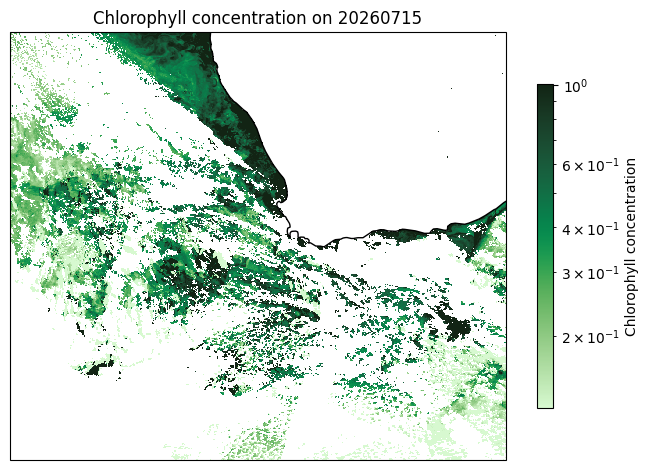

In [5]:
day = '20260715'

log_min = -0.9
log_max = 0.001
lats_chl = chl[day]['latitude'][:]
lons_chl = chl[day]['longitude'][:]

fig, ax = plt.subplots(
    subplot_kw={'projection': ccrs.PlateCarree()},
    figsize=(8, 6)
)

mesh = ax.pcolormesh(
    lons_chl,
    lats_chl,
    10**chl[day].squeeze(),
    transform=ccrs.PlateCarree(),
    cmap=cmocean.cm.algae,
    norm=LogNorm(vmin=10**log_min, vmax=10**log_max)
)

# Add coastlines and colorbar
ax.coastlines()
cbar = plt.colorbar(mesh, ax=ax, orientation='vertical', shrink=0.7)
cbar.set_label("Chlorophyll concentration")

plt.title(f"Chlorophyll concentration on {day}")
plt.show()

In [ ]:
# wget -O "C:\Users\erica\Downloads\20260702_CLS_CHL_5d.nc" https://thredds-x.ipsl.fr/thredds/fileServer/WHIRLS/SATELLITE/CHL/20260704_CLS_CHL_5d.nc

In [2]:
def dm_to_dd(degrees, minutes, flag=False):
    dd = degrees + (minutes / 60)
    if flag:
        dd = -dd
    return dd

def haversine_nm(lon1, lat1, lon2, lat2):
    R = 6371.0  # km
    deg2rad = np.pi / 180.0

    dlon = (lon2 - lon1) * deg2rad
    dlat = (lat2 - lat1) * deg2rad

    a = (np.sin(dlat/2)**2 +
         np.cos(lat1 * deg2rad) * np.cos(lat2 * deg2rad) *
         np.sin(dlon/2)**2)

    c = 2 * np.arcsin(np.sqrt(a))
    km = R * c
    nm = km * 0.539957  # convert km to nautical miles
    return nm
def format_time(h):
    hours = int(h)
    minutes = int(round((h - hours) * 60))
    return hours, minutes

In [75]:
july_day = '09'

date = f'2026-07-{july_day}'
date_chl = f"202607{july_day}"

# date = f'2026-06-30'
# date_chl = f"20260630"

yr = date[0:4]
mnth = date[5:7]
day = date[-2:]
sab_1 = (11.892700, -39.216100)
sab_2 = (11.541100, -38.4758007)
sab_3 = (11.1800, -39.24000)

glider_deployment = (11.54, -37.41)
s1_x, s1_y = sab_1
s2_x, s2_y = sab_2
s3_x, s3_y = sab_3

In [76]:
yr = date[0:4]
mnth = date[5:7]
day = date[-2:]

station_1 = (dm_to_dd(16, 38.247), dm_to_dd(34, 29.976, True))
station_2 = (dm_to_dd(15, 25.675), dm_to_dd(34, 29.963, True))
station_3 = (dm_to_dd(11, 38.167), dm_to_dd(37, 24.128, True))
station_4 = (dm_to_dd(11,57.498), dm_to_dd(38, 9.637, True))
station_5 = (dm_to_dd(11,53.235), dm_to_dd(39, 12.933, True))
station_6 = (dm_to_dd(11,32.443), dm_to_dd(38, 28.558, True))
station_7 = (dm_to_dd(11,39.051), dm_to_dd(39, 23.478, True))
station_8 = (dm_to_dd(11,38.575), dm_to_dd(39, 23.533, True))

glider1 = (11.54, -37.41) # 283 and 284 have been deployed
#284(microrider) 01-07-2026 @ 11:30 UTC -37.4138 11.6210
glider2 = ()
#283(suna) 03-07-2026 @ 11:31 UTC -38.4683 11.5483

In [77]:
##### POSITION VARIABLES #####
ft=10
small_box = True
if small_box is True:
    lon_min, lon_max, lat_min, lat_max = 9, 17, -40, -34
    pos_west,pos_east,pos_south,pos_north  = 9, 17, -40,-34 
    vmin_adt = -0.2
    vmax_adt = 1.2
    title="zoom"
else:
    lon_min, lon_max, lat_min, lat_max = 6, 23, -44, -32
    pos_west,pos_east,pos_south,pos_north  = 6, 23, -44,-32  #Reset the area
    title=""
    vmin_adt = -0.25
    vmax_adt = 1.55
# proj = ccrs.Mercator(central_longitude=(pos_south + pos_north)//2,min_latitude=pos_south+3,max_latitude=pos_north+3)
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent

In [78]:
dir = "Y:\\MD252_WHIRLS\\REP\\data\\"

# sst_path = dir + f"Eddies\{date}\sst\{date.replace("-", "")}_CLS_SST.nc"

dir_adcp = "Y:\\MD252_WHIRLS\\ADCP_FROM_XAVIER\\MD2_OS38_WHIRLS-2026_120s_oceansites.nc"
dir_eddies = dir + f"Eddies\\{date}\\"

save_fig = "Y:\\MD252_WHIRLS\\REP\\figures\\CHL\\"

if not os.path.isdir(save_fig):
    os.makedirs(save_fig)

fname_bathy =  dir + "bathymetry\\etopo2.nc"
ctd_path = "Y:\\MD252_WHIRLS\\CTD\\data"

adt_path= dir + f"daily_adt\\{date}_cmems_data.nc"
# adt_path= f"Y:\\MD252_WHIRLS\\DAILY_adt_sst_toeddies_data\\SSH\\{date}_cmems_data.nc"

# chl_path = f"Y:\\MD252_WHIRLS\\DAILY_adt_sst_toeddies_data\\CHL\\{date_chl}_CLS_CHL_5d.nc"
chl_path = f"Y:\\MD252_WHIRLS\\DAILY_SAT_DATA\\CHL\\{date_chl}_CLS_CHL.nc"

In [79]:
adt_data = nc.Dataset(adt_path)
chl_data = nc.Dataset(chl_path)

In [80]:
lats = adt_data['latitude'][:]
lons = adt_data['longitude'][:]
time = adt_data['time'][:]
adt = adt_data['adt'][:]
ugos = np.squeeze(adt_data['ugos'][:])
vgos = np.squeeze(adt_data['vgos'][:])
current_mag = np.sqrt(ugos**2 + vgos**2)

C:\Users\erica\AppData\Local\Temp\ipykernel_19776\1840043835.py:7: RuntimeWarning: invalid value encountered in sqrt
  current_mag = np.sqrt(ugos**2 + vgos**2)


In [81]:
chl = chl_data['chl_a'][:]

lats_chl = chl_data['latitude'][:]
lons_chl = chl_data['longitude'][:]
time_chl = chl_data['time'][:]
chl = np.squeeze(chl)

In [82]:
path_nav = "Y:\\MD252_WHIRLS\\NAV\\"

files = sorted([f for f in os.listdir(path_nav) if f.endswith('.nav')])

lat_list = []
lon_list = []
for file in files:
    ds = xr.open_dataset(path_nav + file)
    lat_list.append(ds["lat"].values)
    lon_list.append(ds["long"].values)

clean_date = date.replace("-", "")

# Find the exact index matching your day
slice_index = None
for idx, file in enumerate(files):
    if clean_date in file:
        slice_index = idx
        break

# 3. Slice and calculate coordinates (last 2 days)
if slice_index is not None:
    start_idx = max(0, slice_index - 1)  # prevents negative index on the first day

    lat_bato = np.concatenate(lat_list[start_idx:slice_index + 1])
    longs_bato = np.concatenate(lon_list[start_idx:slice_index + 1])

    ship_center = (longs_bato[-1], lat_bato[-1])
    ship_x, ship_y = ship_center

else:
    print(f"Error: Could not find any files matching the date {date}")

# # 3. Slice and calculate coordinates (all MD trajectory)
# if slice_index is not None:
#     # Slices perfectly from day 1 up to your target day
#     lat_bato = np.concatenate(lat_list[:slice_index + 1])
#     longs_bato = np.concatenate(lon_list[:slice_index + 1])
    
#     ship_center = (longs_bato[-1], lat_bato[-1])
#     ship_x, ship_y = ship_center
    
# else:
#     print(f"Error: Could not find any files matching the date {date}")

In [83]:
# lats_sst = sst_data['NbLatitudes']
# lons_sst = sst_data['NbLongitudes']
# time = sst_data['time']
# sst = sst_data['Grid_0001']

# sst = np.where(sst==np.nan, 0, sst)

In [84]:
##### BATHYMETRY #####
bathymetry_data = xr.open_dataset(fname_bathy)
land_feature = cfeature.NaturalEarthFeature(
    category='physical',
    name='land',
    scale='10m',
    edgecolor='black',
    facecolor='gray'
)

# Extract relevant variables (e.g., longitude, latitude, depth)
lon = bathymetry_data['lon']
lat = bathymetry_data['lat']
depth = bathymetry_data['topo']
LON = bathymetry_data['lon']
LAT = bathymetry_data['lat']
depth = bathymetry_data['topo']
lon_subset = LON.sel(lon=slice(lon_min, lon_max))
lat_subset = LAT.sel(lat=slice(lat_min, lat_max))
depth_subset = depth.sel(lon=slice(lon_min, lon_max), lat=slice(lat_min, lat_max))


In [85]:
depth_subset = np.where(depth_subset > 0, 0, depth_subset)

In [86]:
files = os.listdir(dir_eddies)
for fname in files:
    if "anti" in fname:
        if "maxspeed" in fname:
            gdf_ms = gpd.read_file(dir_eddies + fname) # 06-29 #7, 13, 14, 30 invalid
        elif "outcontour" in fname:
            gdf_oc = gpd.read_file(dir_eddies + fname)
        elif "centers" in fname:
            gdf_cent = gpd.read_file(dir_eddies + fname)
        else:
            print(f"Error, no file loaded for {fname}")
    else:
        if "maxspeed" in fname:
            gdfcyc_ms = gpd.read_file(dir_eddies + fname) # 06-29 #7, 13, 14, 30 invalid
        elif "outcontour" in fname:
            gdfcyc_oc = gpd.read_file(dir_eddies + fname)
        elif "centers" in fname:
            gdfcyc_cent = gpd.read_file(dir_eddies + fname)
        else:
            print(f"Error, no file loaded for {fname}")

In [87]:
speed_knots = 6.0
stop_hours = 2.0

points = [
    (ship_x, ship_y),
    (s1_x, s1_y),
    (s2_x, s2_y),
    (s3_x, s3_y),
]

total_time = 0.0
times = []  # cumulative arrival times

for i in range(1, len(points)):
    lon1, lat1 = points[i-1]
    lon2, lat2 = points[i]

    dist_nm = haversine_nm(lon1, lat1, lon2, lat2)
    travel_time = dist_nm / speed_knots  # hours

    total_time += travel_time

    # arrival at point i
    times.append(total_time)

    # add stop time except after final point
    if i < len(points) - 1:
        total_time += stop_hours
curr_t = datetime.now()

In [88]:
# plt.imshow(chl, cmap="viridis", origin="lower")
# plt.colorbar(label="Value")
# plt.show()

In [89]:
chl = chl.squeeze()

In [37]:
longs_bato.shape

(132900,)

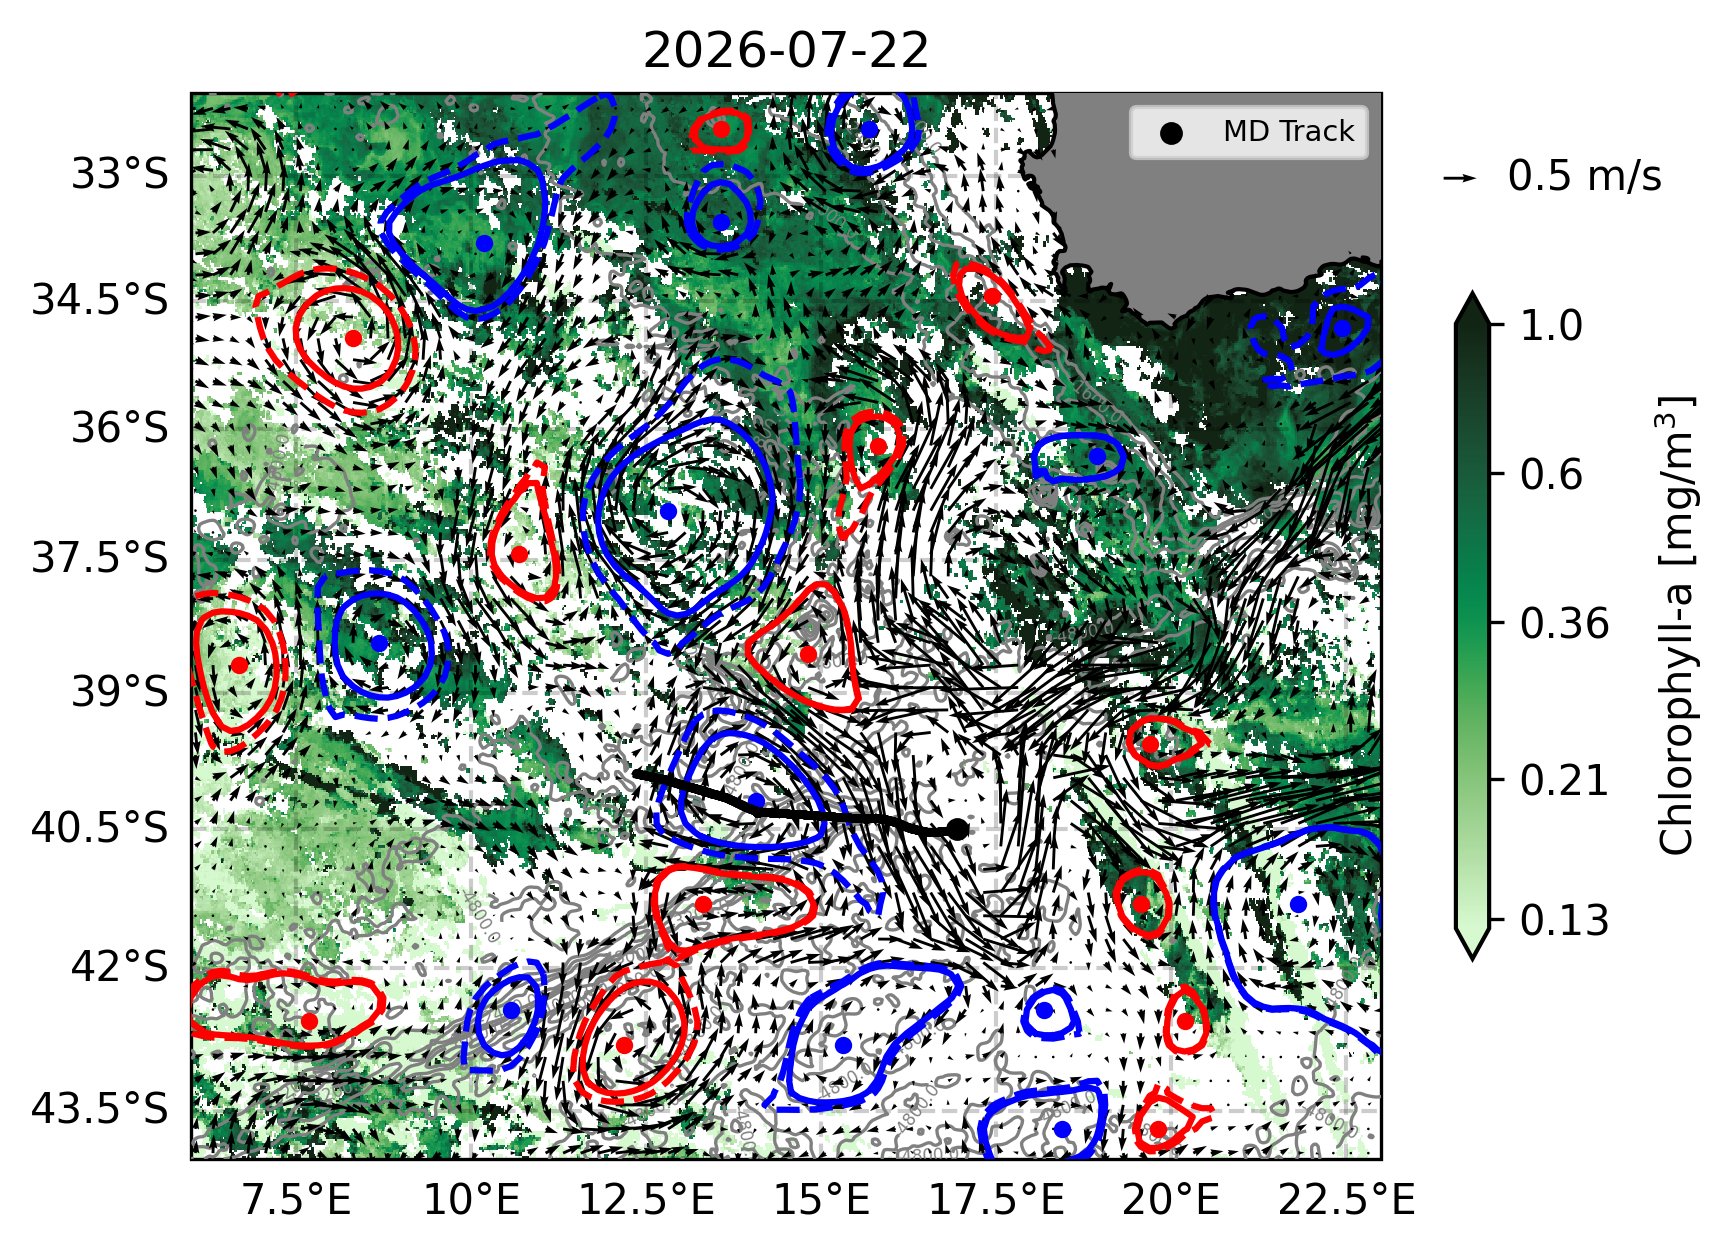

In [38]:
fig = plt.figure(dpi=300)


ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
bathy_contours = np.arange(-5500, 0, 700)
c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="grey", linestyles='solid', transform=crs, linewidths=0.8, zorder=5)
ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

log_min = -0.9
log_max = 0.001

c2 = ax0.pcolormesh(
    lons_chl, 
    lats_chl, 
    10**chl, 
    transform=crs, 
    cmap=cmocean.cm.algae, 
    norm=LogNorm(vmin=10**log_min, vmax=10**log_max)
)
cbar = fig.colorbar(c2, ax=ax0, shrink=0.6, extend='both')
manual_ticks = np.round(np.logspace(log_min, log_max, num=5), 2)
cbar.set_ticks(manual_ticks)
cbar.set_ticklabels([str(tick) for tick in manual_ticks])
cbar.ax.yaxis.set_minor_locator(ticker.NullLocator())
cbar.ax.tick_params(labelsize=10)
cbar.set_label('Chlorophyll-a [mg/m$^3$]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)


# ADT contours
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
Q = ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18, zorder=8)

for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x,y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='red', transform=crs)
        xs,ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
        x_c = gdf_cent['geometry'][i].x
        y_c = gdf_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x,y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='blue', transform=crs)
        xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
        x_c = gdfcyc_cent['geometry'][i].x
        y_c = gdfcyc_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
ax0.scatter(ship_x, ship_y, s=20, color='k', zorder=100, transform=crs, label="MD Track")

h, m = format_time(times[0])
upd_t = curr_t + timedelta(hours=h, minutes=m)

h, m = format_time(times[2])
upd_t = curr_t + timedelta(hours=h, minutes=m)

arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='k', zorder=90)
ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')

leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 
plt.savefig(save_fig + f"{date}_chl.png")
plt.savefig("C:\\Users\\erica\\OneDrive\\Desktop\\PhD\\WHIRLS cruise\\chl maps\\" + f"{date}_chl.png")

In [47]:
lons_chl.shape, lats_chl.shape, chl.shape 

((1131,), (976,), (976, 1131))

# SURFACE DATA WITH FERRYBOX

In [39]:
fluo_dir = Path(r"Z:\TECHSAS\DONNEES\NetCDF\FLUO")
nav_dir = Path(r"Z:\TECHSAS\DONNEES\NetCDF\NAV")

data_fluo = {}
data_nav = {}
days_labels = {}

# Load Fluo files
for filepath in sorted(fluo_dir.glob("*.fluo")):
    date_str = filepath.name.split('-')[0]
    date_obj = datetime.strptime(date_str, "%Y%m%d")
    iso_key = date_obj.strftime("%Y-%m-%d")
    days_labels[iso_key] = f"{date_obj.day} {date_obj.strftime('%B')}"
    data_fluo[iso_key] = xr.open_dataset(filepath)

# Load Nav files
for filepath in sorted(nav_dir.glob("*.nav")):
    date_str = filepath.name.split('-')[0]
    date_obj = datetime.strptime(date_str, "%Y%m%d")
    iso_key = date_obj.strftime("%Y-%m-%d")
    data_nav[iso_key] = xr.open_dataset(filepath)

# Only process days present in BOTH datasets
valid_keys = sorted([k for k in days_labels if k in data_fluo and k in data_nav])

# CODE 1: FLUO TIMESERIES (UNCHANGED LOGIC)
variables = ["CDOM", "Eco_Chlo", "scatter"]
cfg = {
    "CDOM": ['Colored Dissolved Organic Matter', 'ppb'],
    "Eco_Chlo": ['Chlorophyll fluorescence', '$\mu$g/L'],
    "scatter": ['Optical backscatter', '$\mathregular{m^{-1}}$']
}

<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:31: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:31: SyntaxWarning: invalid escape sequence '\m'
C:\Users\erica\AppData\Local\Temp\ipykernel_19776\1571590498.py:30: SyntaxWarning: invalid escape sequence '\m'
  "Eco_Chlo": ['Chlorophyll fluorescence', '$\mu$g/L'],
C:\Users\erica\AppData\Local\Temp\ipykernel_19776\1571590498.py:31: SyntaxWarning: invalid escape sequence '\m'
  "scatter": ['Optical backscatter', '$\mathregular{m^{-1}}$']


Text(0.5, 1.03, 'Ferrybox Measurements')

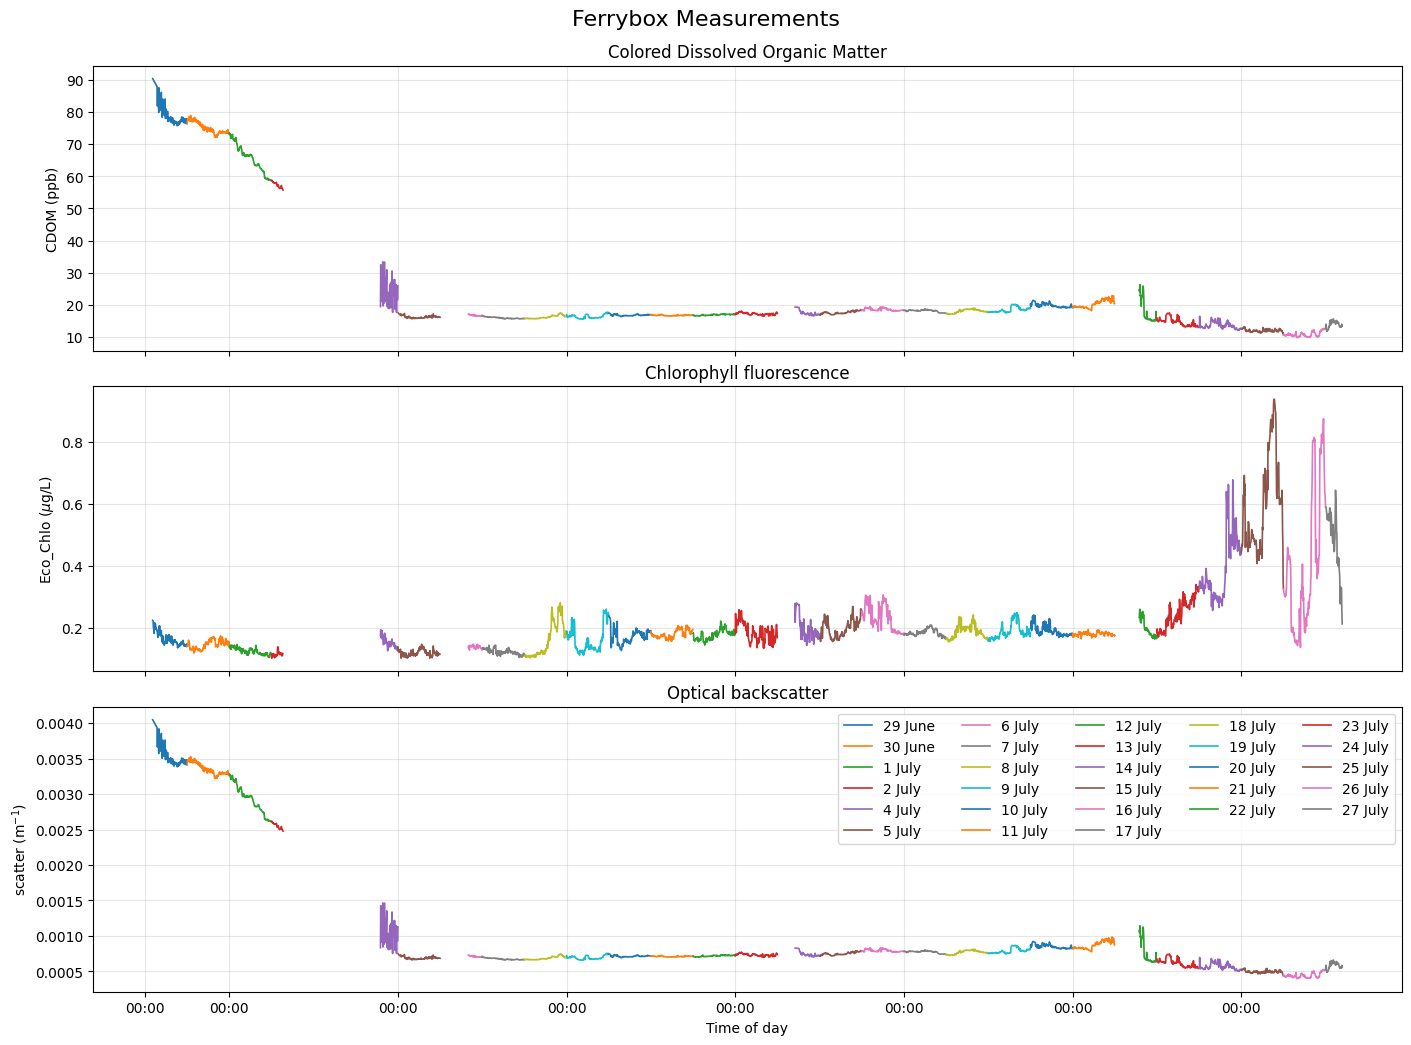

In [40]:
fig1, axes = plt.subplots(len(variables), 1, figsize=(14, 10), sharex=True, constrained_layout=True)

# Use a standard matplotlib color cycle so colors match across both figures
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for ax, var in zip(axes, variables):
    for color_idx, iso_key in enumerate(valid_keys):
        ds = data_fluo[iso_key]
        label = days_labels[iso_key]

        time = ds.time.values
        values = ds[var].values

        mask = np.isfinite(values)
        time = time[mask]
        values = values[mask]

        # IQR outlier removal
        Q1 = np.percentile(values, 25)
        Q3 = np.percentile(values, 75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        mask = (values >= lower) & (values <= upper)
        time = time[mask]
        values = values[mask]

        # Smoothing
        values = pd.Series(values).rolling(window=50, center=True, min_periods=1).mean()

        ax.plot(time[::500], values[::500], lw=1.2, label=label, color=colors[color_idx % len(colors)])

    ax.set_ylabel(f"{var} ({cfg[var][1]})")
    ax.set_title(cfg[var][0])
    ax.grid(alpha=0.3)

axes[-1].legend(ncol=5)
axes[-1].set_xlabel("Time of day")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig1.suptitle('Ferrybox Measurements', y=1.03, fontsize=16)

## ONE SINGLE DAY

In [46]:
nav_1min = data_nav[date].resample(time='1min').mean()
fluo_1min = data_fluo[date].resample(time='1min').mean()

# Make sure both datasets have exactly the same timestamps
fluo_1min = fluo_1min.reindex(time=nav_1min.time)

# Assign ship position as coordinates
fluo_1min = fluo_1min.assign_coords(lat=("time", nav_1min.lat.values), lon=("time", nav_1min.long.values))

In [47]:
# ##### POSITION VARIABLES #####
# ft=10
# small_box = True
# if small_box is True:
#     lon_min, lon_max, lat_min, lat_max = 9, 17, -40, -34
#     pos_west,pos_east,pos_south,pos_north  = 9, 17, -40,-34 
#     vmin_adt = -0.2
#     vmax_adt = 1.2
#     title="zoom"
# else:
#     lon_min, lon_max, lat_min, lat_max = 6, 23, -44, -32
#     pos_west,pos_east,pos_south,pos_north  = 6, 23, -44,-32  #Reset the area
#     title=""
#     vmin_adt = -0.25
#     vmax_adt = 1.55
# # proj = ccrs.Mercator(central_longitude=(pos_south + pos_north)//2,min_latitude=pos_south+3,max_latitude=pos_north+3)
# proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

# crs = ccrs.PlateCarree()
# extent=[pos_west, pos_east, pos_south, pos_north]
# cartmap = proj,crs,extent

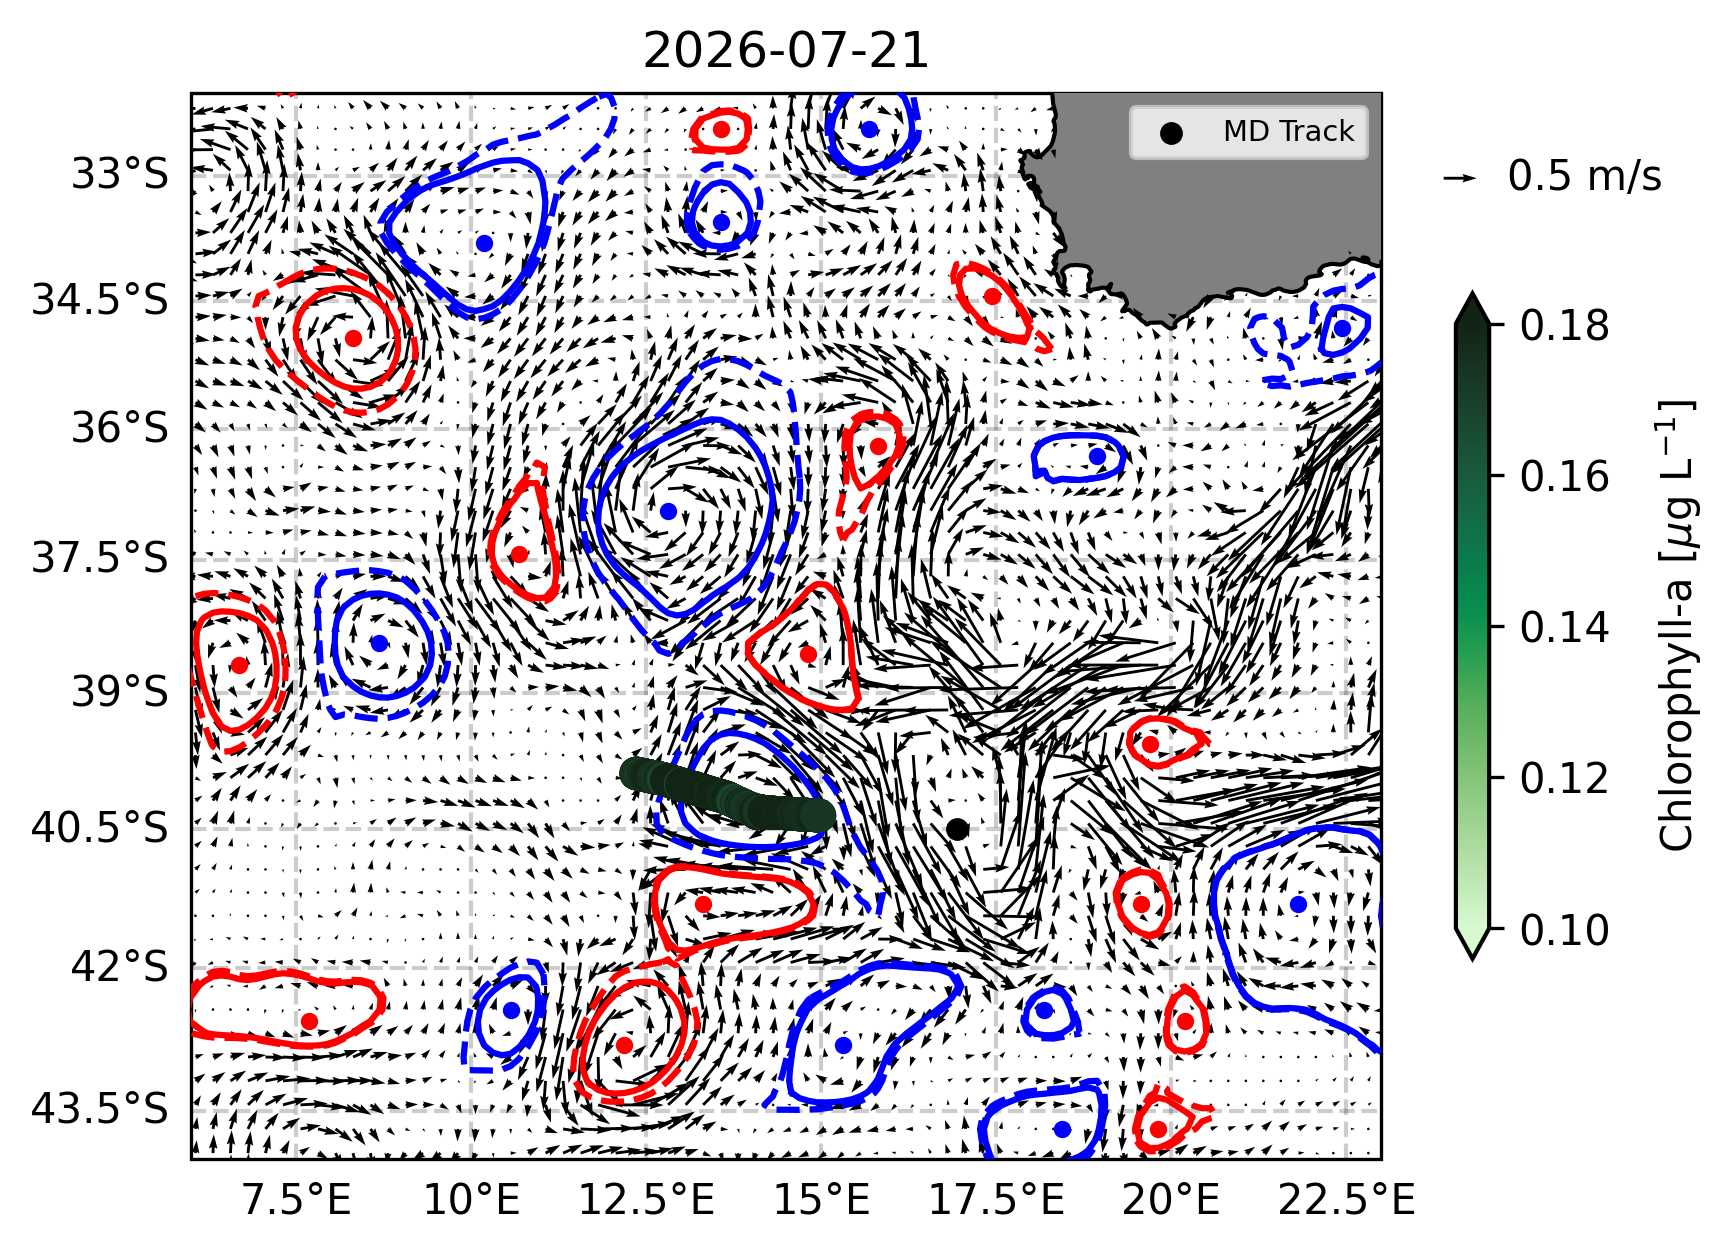

In [48]:
lat, lon = nav_1min.lat.values, nav_1min.long.values

fig = plt.figure(dpi=300)

ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot bathymetric relief
bathy_contours = np.arange(-5500, 0, 700)

# log_min = -0.9
# log_max = 0.001

c2 = ax0.scatter(
    lon, lat,
    c=fluo_1min.Eco_Chlo,
    s=50,
    cmap=cmocean.cm.algae,
    vmin=0.1,
    vmax=0.18,
    zorder=15,
    transform=crs
)
cbar = fig.colorbar(c2, ax=ax0, shrink=0.6, extend='both')
cbar.ax.tick_params(labelsize=10)
cbar.set_label('Chlorophyll-a [$\\mu$g L$^{-1}$]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

# ADT contours
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
Q = ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18, zorder=8)

for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x,y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='red', transform=crs)
        xs,ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
        x_c = gdf_cent['geometry'][i].x
        y_c = gdf_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x,y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, zorder=10, color='blue', transform=crs)
        xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
        x_c = gdfcyc_cent['geometry'][i].x
        y_c = gdfcyc_cent['geometry'][i].y
        ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
ax0.scatter(ship_x, ship_y, s=20, color='k', zorder=100, transform=crs, label="MD Track")

h, m = format_time(times[0])
upd_t = curr_t + timedelta(hours=h, minutes=m)

h, m = format_time(times[2])
upd_t = curr_t + timedelta(hours=h, minutes=m)

arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
# ax0.scatter(longs_bato[::50],lat_bato[::50], s=0.4, transform=crs, color='k', zorder=90)
ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')

leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 
plt.savefig("C:\\Users\\erica\\OneDrive\\Desktop\\PhD\\WHIRLS cruise\\traj chl maps\\" + f"{date}_traj_surf_chl.png")

### TRANSECT

In [54]:
transect = ['2026-07-04', '2026-07-05', '2026-07-06', '2026-07-07', '2026-07-08', '2026-07-09']

nav_1min = {}
fluo_1min = {}

for day in transect:
    # Resample to 1-minute resolution
    nav_1min[day] = data_nav[day].resample(time='1min').mean()
    fluo_1min[day] = data_fluo[day].resample(time='1min').mean()

    # Match timestamps
    fluo_1min[day] = fluo_1min[day].reindex(time=nav_1min[day].time)

    # Add ship position
    fluo_1min[day] = fluo_1min[day].assign_coords(
        lat=("time", nav_1min[day].lat.values),
        lon=("time", nav_1min[day].long.values)
    )

C:\Users\erica\AppData\Local\Temp\ipykernel_19776\2709263353.py:125: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  leg = ax0.legend(fontsize='x-small', loc='upper right')


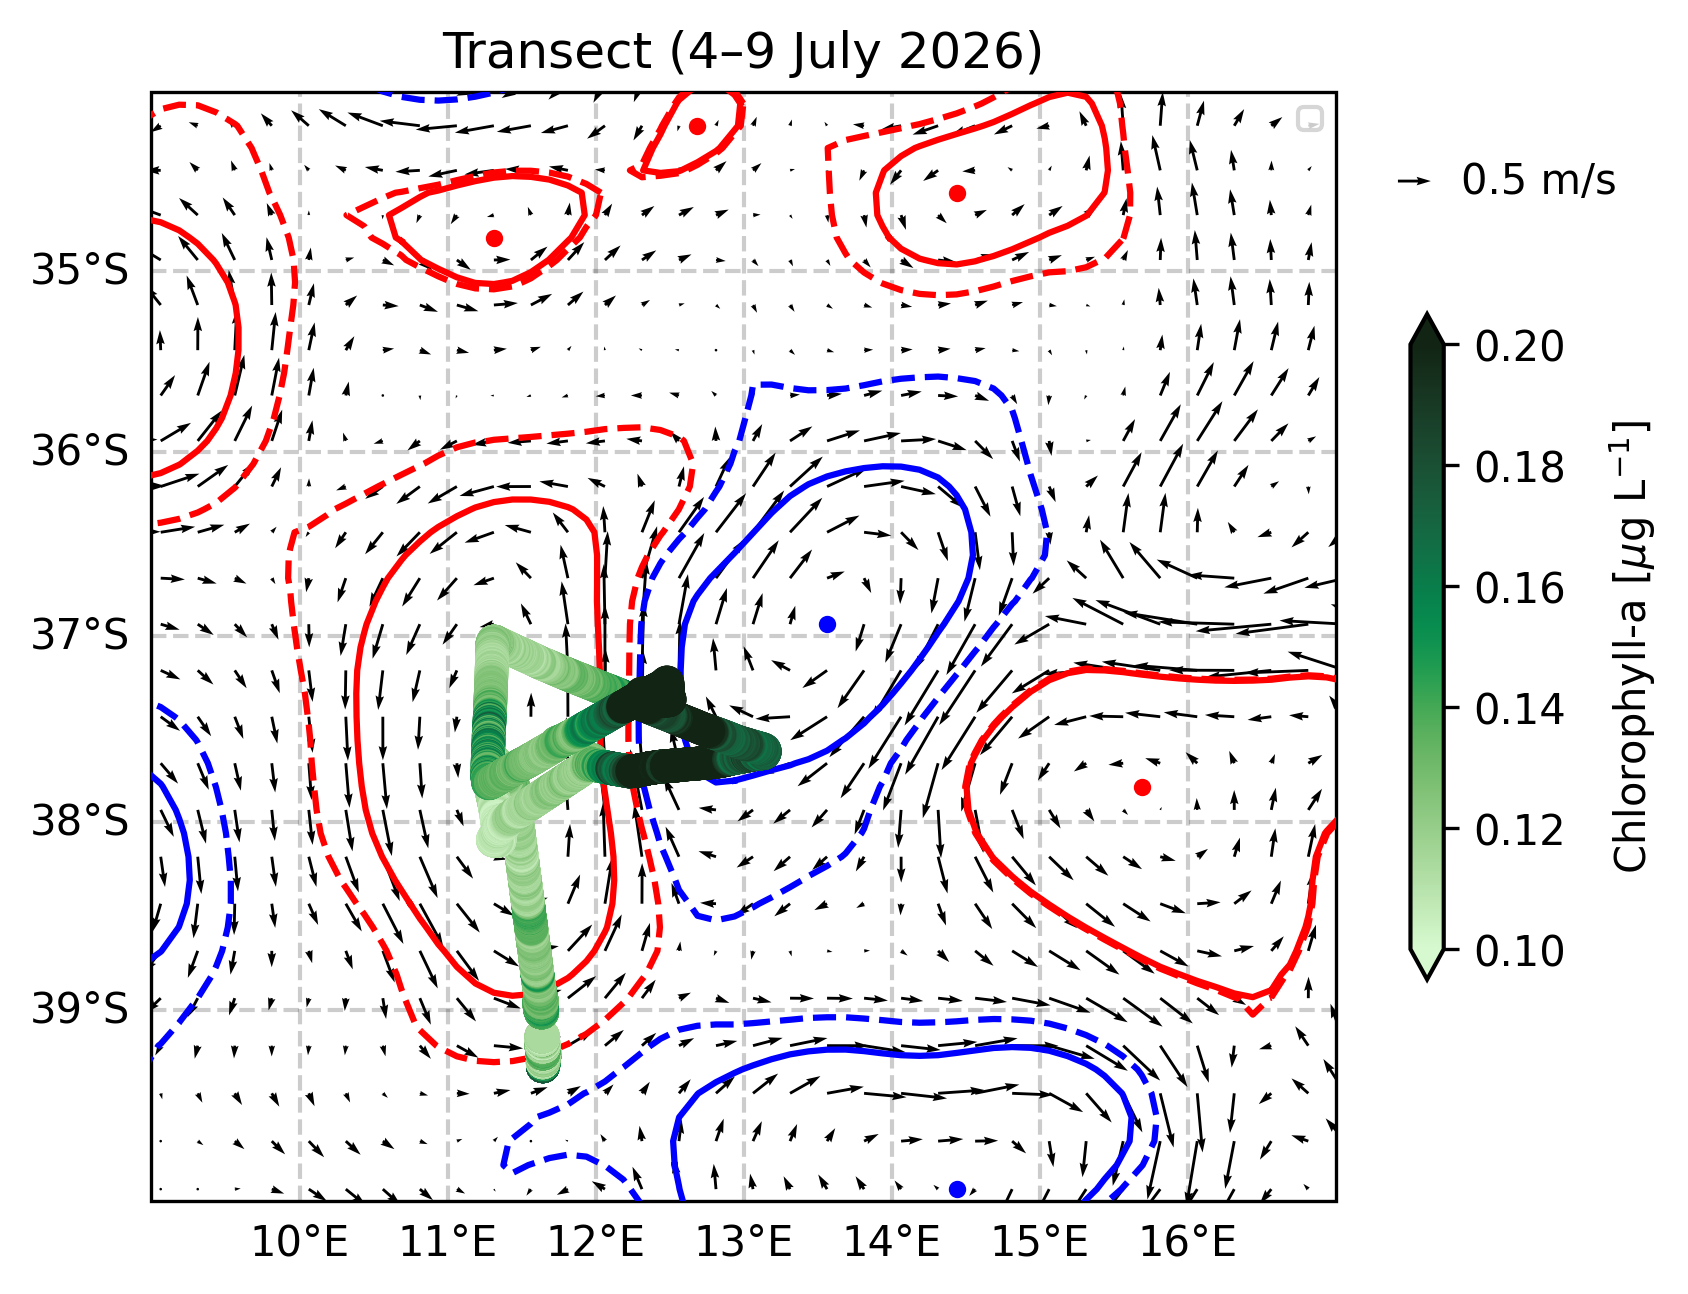

In [92]:
fig = plt.figure(dpi=300)

ax0 = fig.add_subplot(1, 1, 1, projection=proj, zorder=3)
ax0.set_title("Transect (4–9 July 2026)")

ax0.add_feature(
    cfeature.LAND,
    linewidth=0.5,
    edgecolor='black',
    facecolor='gray',
    zorder=4
)
ax0.coastlines(resolution='10m', color='k', linestyle='-', zorder=5)

ax0.set_extent(extent)

map_grid = ax0.gridlines(
    linewidth=1,
    color='black',
    alpha=0.2,
    linestyle='--',
    draw_labels=True,
    zorder=6
)
map_grid.top_labels = False
map_grid.right_labels = False
map_grid.left_labels = True
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}

# Plot all four days
for day in transect:

    c2 = ax0.scatter(
        nav_1min[day].long.values,
        nav_1min[day].lat.values,
        c=fluo_1min[day].Eco_Chlo,
        s=50,
        cmap=cmocean.cm.algae,
        vmin=0.1,
        vmax=0.2,
        transform=crs,
        zorder=15,
    )

# Colorbar
cbar = fig.colorbar(c2, ax=ax0, shrink=0.6, extend='both')
cbar.ax.tick_params(labelsize=10)
cbar.set_label('Chlorophyll-a [$\\mu$g L$^{-1}$]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)

# ADT currents
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2

Q = ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18,
    zorder=8,
)

# Mesoscale structures
for i in range(len(gdf_cent)):
    if gdf_ms['geometry'][i] is not None:
        x, y = gdf_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, color='red', zorder=10, transform=crs)

        xs, ys = gdf_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, color='red', linestyle='--', zorder=10, transform=crs)

        ax0.scatter(
            gdf_cent['geometry'][i].x,
            gdf_cent['geometry'][i].y,
            s=10,
            color='red',
            zorder=10,
            transform=crs,
        )

for i in range(len(gdfcyc_cent)):
    if gdfcyc_ms['geometry'][i] is not None:
        x, y = gdfcyc_ms['geometry'][i].exterior.xy
        ax0.plot(x, y, color='blue', zorder=10, transform=crs)

        xs, ys = gdfcyc_oc['geometry'][i].exterior.xy
        ax0.plot(xs, ys, color='blue', linestyle='--', zorder=10, transform=crs)

        ax0.scatter(
            gdfcyc_cent['geometry'][i].x,
            gdfcyc_cent['geometry'][i].y,
            s=10,
            color='blue',
            zorder=10,
            transform=crs,
        )

# Ship track
# ax0.scatter(
#     ship_x,
#     ship_y,
#     s=20,
#     color='k',
#     zorder=100,
#     transform=crs,
#     label='MD Track'
# )

# # Bato positions
# ax0.scatter(
#     longs_bato[::50],
#     lat_bato[::50],
#     s=1,
#     color='k',
#     transform=crs,
#     zorder=90,
# )

# Quiver key
ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')

leg = ax0.legend(fontsize='x-small', loc='upper right')
leg.set_zorder(100)

plt.savefig("C:\\Users\\erica\\OneDrive\\Desktop\\PhD\\WHIRLS cruise\\traj chl maps\\transect_4-7_July_traj_surf_chl.png")
plt.show()

In [ ]:
# all_lon = []
# all_lat = []
# all_chl = []

# # Loop over all available days
# for day in data_fluo.keys():

#     # Skip days not present in navigation
#     if day not in data_nav:
#         continue

#     # Resample to 1 minute
#     nav_1min = data_nav[day].resample(time='1min').mean()
#     fluo_1min = data_fluo[day].resample(time='1min').mean()

#     # Align timestamps
#     fluo_1min = fluo_1min.reindex(time=nav_1min.time)

#     # Keep only valid values
#     mask = (
#         np.isfinite(nav_1min.long) &
#         np.isfinite(nav_1min.lat) &
#         np.isfinite(fluo_1min.Eco_Chlo)
#     )

#     all_lon.append(nav_1min.long.values[mask])
#     all_lat.append(nav_1min.lat.values[mask])
#     all_chl.append(fluo_1min.Eco_Chlo.values[mask])

# # Concatenate all days
# all_lon = np.concatenate(all_lon)
# all_lat = np.concatenate(all_lat)
# all_chl = np.concatenate(all_chl)

In [183]:
# lat, lon = nav_1min.lat.values, nav_1min.long.values

# fig = plt.figure(dpi=300)

# ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
# ax0.set_title(f'{date}')
# ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
# ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
# ax0.set_extent(extent)
# map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
# map_grid.top_labels = False
# map_grid.left_labels = True
# map_grid.right_labels = False
# map_grid.xlabel_style = {'size': ft}
# map_grid.ylabel_style = {'size': ft}

# # Plot bathymetric relief
# bathy_contours = np.arange(-5500, 0, 700)

# # log_min = -0.9
# # log_max = 0.001

# c2 = ax0.scatter(
#     all_lon,
#     all_lat,
#     c=all_chl,
#     s=10,
#     cmap=cmocean.cm.algae,
#     vmin=0.10,
#     vmax=0.16,
#     transform=crs,
#     zorder=15,
# )

# cbar = fig.colorbar(c2, ax=ax0, shrink=0.6, extend='both')
# cbar.ax.tick_params(labelsize=10)
# cbar.set_label('Chlorophyll-a [$\\mu$g L$^{-1}$]', fontsize=10, labelpad=10)
# cbar.outline.set_linewidth(1)

# # ADT contours
# lon_2D, lat_2D = np.meshgrid(lons, lats)
# step = 2
# Q = ax0.quiver(
#     lon_2D[::step, ::step],
#     lat_2D[::step, ::step],
#     ugos[::step, ::step],
#     vgos[::step, ::step],
#     transform=crs,
#     scale=18, zorder=8)

# for i in range(len(gdf_cent)):
#     if gdf_ms['geometry'][i] is not None:
#         x,y = gdf_ms['geometry'][i].exterior.xy
#         ax0.plot(x, y, zorder=10, color='red', transform=crs)
#         xs,ys = gdf_oc['geometry'][i].exterior.xy
#         ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
#         x_c = gdf_cent['geometry'][i].x
#         y_c = gdf_cent['geometry'][i].y
#         ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

# for i in range(len(gdfcyc_cent)):
#     if gdfcyc_ms['geometry'][i] is not None:
#         x,y = gdfcyc_ms['geometry'][i].exterior.xy
#         ax0.plot(x, y, zorder=10, color='blue', transform=crs)
#         xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
#         ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
#         x_c = gdfcyc_cent['geometry'][i].x
#         y_c = gdfcyc_cent['geometry'][i].y
#         ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
# ax0.scatter(ship_x, ship_y, s=20, color='k', zorder=100, transform=crs, label="MD Track")

# h, m = format_time(times[0])
# upd_t = curr_t + timedelta(hours=h, minutes=m)

# h, m = format_time(times[2])
# upd_t = curr_t + timedelta(hours=h, minutes=m)

# arrow_handle = FancyArrowPatch(
#     (0, 0), (1, 0),
#     arrowstyle='->',
#     mutation_scale=10,
#     color='k'
# )
# arrow_handle = FancyArrowPatch(
#     (0, 0), (1, 0),
#     arrowstyle='->',
#     mutation_scale=10,
#     color='k'
# )
# # ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='k', zorder=90)
# ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')

# leg = plt.legend(fontsize='x-small', loc = 'upper right')
# leg.set_zorder(100) 